Customer Churn Prediction Using Neural Networks

Internship: Codveda Technologies, Machine Learning

Level: Level 3, Advanced

Task: Neural Networks using TensorFlow/Keras

Objective: Develop a neural network classification model to predict customer churn using customer account information, service usage, and customer support data.

Tools: Python, pandas, Matplotlib, scikit-learn, TensorFlow, and Keras.

Evaluation metrics: Accuracy, confusion matrix, precision, recall, and F1-score.

In [ ]:
import pandas as pd

file_id = "1YF73QNFjNYNnqqN2vHymT3NQG3qwd4RD"
url = f"https://drive.google.com/uc?export=download&id={file_id}"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (2666, 20)


,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [ ]:
# Remove duplicate records
df_cleaned = df.drop_duplicates().copy()

# Separate input features and target
X = df_cleaned.drop(columns=["Churn"])
y = df_cleaned["Churn"].astype(int)

print("Dataset shape after cleaning:", df_cleaned.shape)
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Dataset shape after cleaning: (2666, 20)
Feature shape: (2666, 19)
Target shape: (2666,)

Target distribution:
Churn
0    2278
1     388
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Identify feature types
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Numeric preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Fit preprocessing on training data only
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Convert sparse matrices to dense arrays for TensorFlow
X_train_processed = X_train_processed.toarray() if hasattr(
    X_train_processed, "toarray"
) else X_train_processed

X_test_processed = X_test_processed.toarray() if hasattr(
    X_test_processed, "toarray"
) else X_test_processed

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)
print("Preprocessing completed successfully!")

Training data shape: (2132, 71)
Testing data shape: (534, 71)
Preprocessing completed successfully!


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

# Set a reproducible random seed
tf.keras.utils.set_random_seed(42)

# Build the model
model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,849 (11.13 KB)

 Trainable params: 2,849 (11.13 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train_processed,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

print("Neural network training completed!")

Epoch 1/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.8000 - loss: 0.5417 - val_accuracy: 0.8337 - val_loss: 0.4554
Epoch 2/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8604 - loss: 0.3967 - val_accuracy: 0.8337 - val_loss: 0.4070
Epoch 3/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8610 - loss: 0.3529 - val_accuracy: 0.8337 - val_loss: 0.3798
Epoch 4/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8628 - loss: 0.3244 - val_accuracy: 0.8384 - val_loss: 0.3533
Epoch 5/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8815 - loss: 0.3003 - val_accuracy: 0.8595 - val_loss: 0.3284
Epoch 6/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8944 - loss: 0.2803 - val_accuracy: 0.8689 - val_loss: 0.3113
Epoch 7/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9009 - loss: 0.2554 - val_accuracy: 0.8735 - val_loss: 0.3008
Epoch 8/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9103 - loss: 0.2443 - val_accuracy: 0.8829 - val_los

In [ ]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Predict churn probabilities
y_prob = model.predict(X_test_processed).ravel()

# Convert probabilities to class predictions
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
Accuracy: 0.882

Confusion Matrix:
[[439  17]
 [ 46  32]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.96      0.93       456
           1       0.65      0.41      0.50        78

    accuracy                           0.88       534
   macro avg       0.78      0.69      0.72       534
weighted avg       0.87      0.88      0.87       534



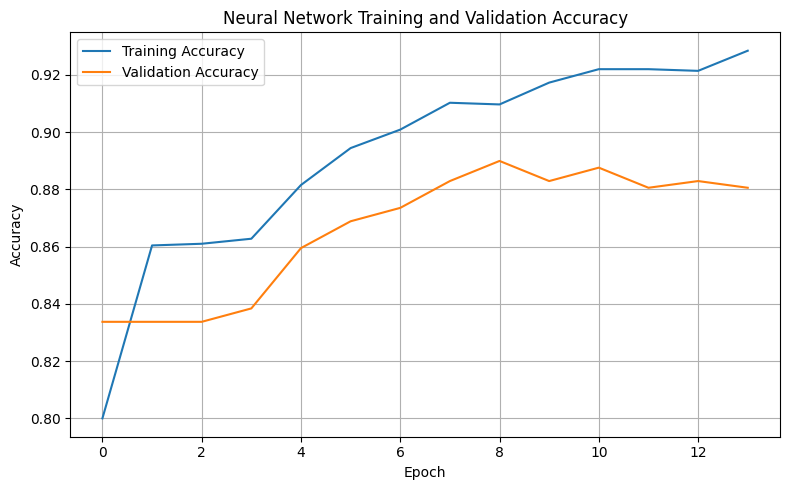

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Neural Network Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
model.save("codveda_churn_neural_network.keras")

print("Neural network model saved successfully!")

Neural network model saved successfully!
